In [3]:
import pandas as pd
from pathlib import Path

RAW = Path("../data/raw/swat")        # use the root-based version from before if the cwd differs

def load_swat(path):
    df = pd.read_csv(path, low_memory=False)
    if str(df.columns[0]).startswith("Unnamed"):     # stage row used as header, so re-read with the real one
        df = pd.read_csv(path, header=1, low_memory=False)
    df.columns = df.columns.str.strip()
    return df

normal = load_swat(RAW / "SWaT_Dataset_Normal_v1.csv")
attack = load_swat(RAW / "SWaT_Dataset_Attack_v0.csv")   # use your actual file name

for name, df in [("normal", normal), ("attack", attack)]:
    print(name, df.shape)
print(normal.columns.tolist())
print(normal.head(3))
print(attack["Normal/Attack"].value_counts())
print(normal["Normal/Attack"].value_counts())

normal (495000, 53)
attack (449919, 53)
['Timestamp', 'FIT101', 'LIT101', 'MV101', 'P101', 'P102', 'AIT201', 'AIT202', 'AIT203', 'FIT201', 'MV201', 'P201', 'P202', 'P203', 'P204', 'P205', 'P206', 'DPIT301', 'FIT301', 'LIT301', 'MV301', 'MV302', 'MV303', 'MV304', 'P301', 'P302', 'AIT401', 'AIT402', 'FIT401', 'LIT401', 'P401', 'P402', 'P403', 'P404', 'UV401', 'AIT501', 'AIT502', 'AIT503', 'AIT504', 'FIT501', 'FIT502', 'FIT503', 'FIT504', 'P501', 'P502', 'PIT501', 'PIT502', 'PIT503', 'FIT601', 'P601', 'P602', 'P603', 'Normal/Attack']
                Timestamp  FIT101    LIT101  MV101  P101  P102    AIT201  \
0   22/12/2015 4:30:00 PM     0.0  124.3135      1     1     1  251.9226   
1   22/12/2015 4:30:01 PM     0.0  124.3920      1     1     1  251.9226   
2   22/12/2015 4:30:02 PM     0.0  124.4705      1     1     1  251.9226   

     AIT202    AIT203  FIT201  ...  P501  P502    PIT501  PIT502  PIT503  \
0  8.313446  312.7916     0.0  ...     1     1  9.100231     0.0  3.3485   
1  8.3

In [4]:
for df in (normal, attack):
    df["Timestamp"] = pd.to_datetime(df["Timestamp"].str.strip(), dayfirst=True)

# The label column has typos in some SWaT releases (e.g. "A ttack"), so normalize it
attack["label"] = (attack["Normal/Attack"].str.replace(" ", "").str.strip()
                   .str.lower().eq("attack").astype(int))
normal["label"] = (normal["Normal/Attack"].str.replace(" ", "").str.strip()
                   .str.lower().eq("attack").astype(int))

for name, df in [("normal", normal), ("attack", attack)]:
    step = df["Timestamp"].diff().dropna()
    print(name, df["Timestamp"].min(), "->", df["Timestamp"].max())
    print("  steps != 1s:", (step != pd.Timedelta(seconds=1)).sum(),
          "| dup timestamps:", df["Timestamp"].duplicated().sum(),
          "| NaNs:", df.isna().sum().sum(),
          "| attack rows:", df["label"].sum())

C:\Users\sidra\AppData\Local\Temp\ipykernel_19524\4178694648.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Timestamp"] = pd.to_datetime(df["Timestamp"].str.strip(), dayfirst=True)


normal 2015-12-22 16:30:00 -> 2015-12-28 09:59:59
  steps != 1s: 0 | dup timestamps: 0 | NaNs: 0 | attack rows: 0
attack 2015-12-28 10:00:00 -> 2016-01-02 14:59:59
  steps != 1s: 1 | dup timestamps: 0 | NaNs: 0 | attack rows: 54621


In [7]:
seg_id = (attack["label"].diff().fillna(0) != 0).cumsum()
segs = (attack[attack["label"] == 1]
        .groupby(seg_id)["Timestamp"].agg(start="min", end="max", rows="count"))
segs["duration_s"] = (segs["end"] - segs["start"]).dt.total_seconds() + 1
print(len(segs), "attack segments")
segs

35 attack segments


,start,end,rows,duration_s
label,,,,
1,2015-12-28 10:29:14,2015-12-28 10:44:53,940,940.0
3,2015-12-28 10:51:08,2015-12-28 10:58:30,443,443.0
5,2015-12-28 11:22:00,2015-12-28 11:28:22,383,383.0
7,2015-12-28 11:47:39,2015-12-28 11:54:08,390,390.0
9,2015-12-28 12:00:55,2015-12-28 12:04:10,196,196.0
11,2015-12-28 12:08:25,2015-12-28 12:15:33,429,429.0
13,2015-12-28 13:10:10,2015-12-28 13:26:13,964,964.0
15,2015-12-28 14:16:20,2015-12-28 14:28:20,721,721.0
17,2015-12-29 06:30:00,2015-12-29 06:42:00,721,721.0


In [8]:
seg_id = (attack["label"].diff().fillna(0) != 0).cumsum()
segs = (attack[attack["label"] == 1]
        .groupby(seg_id)["Timestamp"].agg(start="min", end="max", rows="count"))
segs["duration_s"] = (segs["end"] - segs["start"]).dt.total_seconds() + 1

segs = segs.sort_values("start").reset_index(drop=True)
segs["gap_before_s"] = (segs["start"] - segs["end"].shift()).dt.total_seconds() - 1

print(len(segs), "attack segments")
print(segs["duration_s"].describe())
print("gaps <= 60 s:", (segs["gap_before_s"] <= 60).sum(),
      "| gaps <= 600 s:", (segs["gap_before_s"] <= 600).sum())
segs

35 attack segments
count       35.000000
mean      1560.600000
std       5985.260554
min        101.000000
25%        344.000000
50%        444.000000
75%        719.000000
max      35900.000000
Name: duration_s, dtype: float64
gaps <= 60 s: 1 | gaps <= 600 s: 10


,start,end,rows,duration_s,gap_before_s
0,2015-12-28 10:29:14,2015-12-28 10:44:53,940,940.0,NaN
1,2015-12-28 10:51:08,2015-12-28 10:58:30,443,443.0,374.0
2,2015-12-28 11:22:00,2015-12-28 11:28:22,383,383.0,1409.0
3,2015-12-28 11:47:39,2015-12-28 11:54:08,390,390.0,1156.0
4,2015-12-28 12:00:55,2015-12-28 12:04:10,196,196.0,406.0
5,2015-12-28 12:08:25,2015-12-28 12:15:33,429,429.0,254.0
6,2015-12-28 13:10:10,2015-12-28 13:26:13,964,964.0,3276.0
7,2015-12-28 14:16:20,2015-12-28 14:28:20,721,721.0,3006.0
8,2015-12-29 06:30:00,2015-12-29 06:42:00,721,721.0,57699.0
9,2015-12-29 11:11:25,2015-12-29 11:15:17,233,233.0,16164.0


In [6]:
feature_cols = [c for c in normal.columns if c not in ("Timestamp", "Normal/Attack", "label")]
print(len(feature_cols), "features (expect 51)")

stage = pd.Series({c: next((ch for ch in c if ch.isdigit()), "?") for c in feature_cols})
print(stage.value_counts().sort_index())      # P1..P6 sizes (the stage digit is the first digit in the name)

nunique = normal[feature_cols].nunique()
print("Constant columns:", nunique[nunique == 1].index.tolist())
print("Likely actuators (<=5 unique values):", nunique[nunique <= 5].index.tolist())

51 features (expect 51)
1     5
2    11
3     9
4     9
5    13
6     4
Name: count, dtype: int64
Constant columns: ['P102', 'P201', 'P202', 'P204', 'P206', 'P401', 'P403', 'P404', 'P502', 'P601', 'P603']
Likely actuators (<=5 unique values): ['MV101', 'P101', 'P102', 'MV201', 'P201', 'P202', 'P203', 'P204', 'P205', 'P206', 'MV301', 'MV302', 'MV303', 'MV304', 'P301', 'P302', 'P401', 'P402', 'P403', 'P404', 'UV401', 'P501', 'P502', 'P601', 'P602', 'P603']


In [9]:
import numpy as np, matplotlib.pyplot as plt, os
os.makedirs("../reports/figures", exist_ok=True)

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#52514e", "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False,
})

for df in (normal, attack):
    df[feature_cols] = df[feature_cols].apply(pd.to_numeric, errors="coerce")

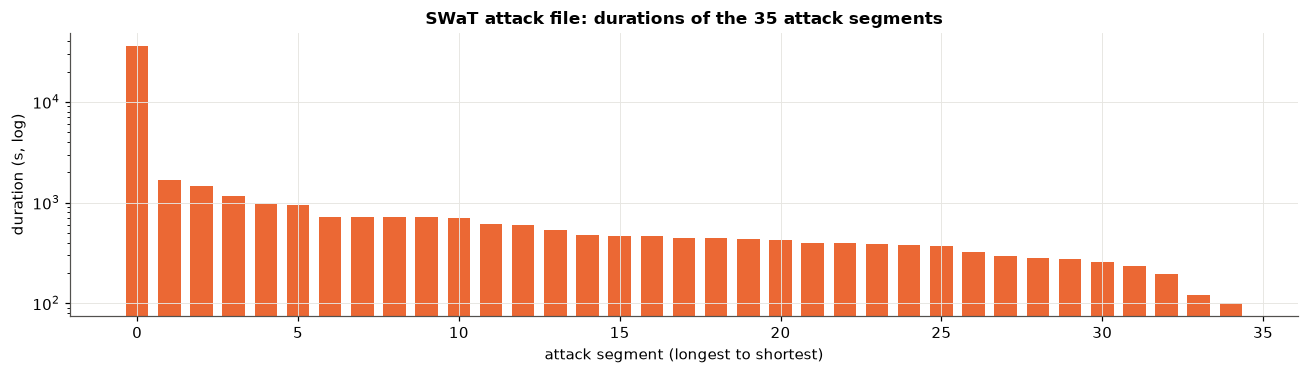

In [10]:
d = segs.sort_values("duration_s", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(range(len(d)), d["duration_s"], color=ORANGE, width=0.7)
ax.set_yscale("log")
ax.set_xlabel("attack segment (longest to shortest)")
ax.set_ylabel("duration (s, log)")
ax.set_title(f"SWaT attack file: durations of the {len(d)} attack segments")
plt.tight_layout()
plt.savefig("../reports/figures/swat_segment_durations.png", dpi=150)
plt.show()

In [11]:
feats = feature_cols
nu = normal[feats].nunique()
disc = [c for c in feats if nu[c] <= 5]       # actuators / constant columns: test for unseen states
cont = [c for c in feats if nu[c] > 5]        # continuous sensors: test for values outside the normal min/max

lo, hi = normal[cont].min(), normal[cont].max()
oor_cont = (attack[cont] < lo) | (attack[cont] > hi)
oor_disc = pd.DataFrame({c: ~attack[c].isin(normal[c].unique()) for c in disc})
oor = pd.concat([oor_cont, oor_disc], axis=1)[feats]      # True = outside what the normal file ever showed

# control: how often is each feature "out of range" when NO attack is running?
base = oor[attack["label"] == 0].mean()
unreliable = base[base > 0.02].index.tolist()
print("Features out of range >2% of the time even without attacks (excluded):", unreliable)
usable = [c for c in feats if c not in unreliable]

rows = []
for i, s in segs.iterrows():
    m = attack["Timestamp"].between(s["start"], s["end"])
    frac = oor.loc[m, usable].mean().sort_values(ascending=False)
    rows.append({"seg": i, "start": s["start"], "duration_s": s["duration_s"],
                 "top_feature": frac.index[0], "max_frac_oor": round(frac.iloc[0], 3),
                 "n_feats_over_50pct": int((frac >= 0.5).sum())})
det = pd.DataFrame(rows)
det["single_sensor"] = pd.cut(det["max_frac_oor"], [-0.01, 0.05, 0.5, 1.0],
                              labels=["hidden", "partial", "visible"])
print(det["single_sensor"].value_counts())
det

Features out of range >2% of the time even without attacks (excluded): ['AIT201', 'AIT203', 'P201', 'AIT402', 'AIT502']
single_sensor
hidden     17
visible    16
partial     2
Name: count, dtype: int64


,seg,start,duration_s,top_feature,max_frac_oor,n_feats_over_50pct,single_sensor
0,0,2015-12-28 10:29:14,940.0,LIT101,1.000,1,visible
1,1,2015-12-28 10:51:08,443.0,FIT201,0.977,2,visible
2,2,2015-12-28 11:22:00,383.0,LIT101,0.313,0,partial
3,3,2015-12-28 11:47:39,390.0,FIT101,0.000,0,hidden
4,4,2015-12-28 12:00:55,196.0,AIT202,0.903,1,visible
5,5,2015-12-28 12:08:25,429.0,LIT301,0.951,1,visible
6,6,2015-12-28 13:10:10,964.0,DPIT301,0.980,1,visible
7,7,2015-12-28 14:16:20,721.0,AIT501,0.639,1,visible
8,8,2015-12-29 06:30:00,721.0,FIT101,0.000,0,hidden
9,9,2015-12-29 11:11:25,233.0,FIT101,0.000,0,hidden


In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

use = [c for c in feats if normal[c].std() > 0]
sc = StandardScaler().fit(normal[use])
Xn, Xa = sc.transform(normal[use]), sc.transform(attack[use])

pca = PCA(n_components=0.95, svd_solver="full").fit(Xn)
print("PCA components kept:", pca.n_components_, "of", len(use))

def recon_err(X):
    return ((X - pca.inverse_transform(pca.transform(X))) ** 2).sum(axis=1)

thr = np.percentile(recon_err(Xn), 99.9)             # threshold from normal data only
flag = recon_err(Xa) > thr
print("Flagged rate on non-attack rows of attack file:", round(flag[attack["label"].values == 0].mean(), 3))

det["pca_frac_flagged"] = [round(flag[attack["Timestamp"].between(s["start"], s["end"]).values].mean(), 3)
                           for _, s in segs.iterrows()]
det["pca_detects"] = det["pca_frac_flagged"] >= 0.5
print(pd.crosstab(det["single_sensor"], det["pca_detects"], margins=True))
det.sort_values("max_frac_oor")

PCA components kept: 14 of 40
Flagged rate on non-attack rows of attack file: 0.5
pca_detects    False  True  All
single_sensor                  
hidden             9     8   17
partial            2     0    2
visible            7     9   16
All               18    17   35


,seg,start,duration_s,top_feature,max_frac_oor,n_feats_over_50pct,single_sensor,pca_frac_flagged,pca_detects
3,3,2015-12-28 11:47:39,390.0,FIT101,0.000,0,hidden,0.000,False
15,15,2015-12-29 18:30:00,721.0,FIT101,0.000,0,hidden,0.000,False
13,13,2015-12-29 18:10:43,259.0,FIT101,0.000,0,hidden,0.008,False
12,12,2015-12-29 14:38:12,717.0,FIT101,0.000,0,hidden,0.000,False
11,11,2015-12-29 11:57:25,276.0,FIT101,0.000,0,hidden,0.000,False
10,10,2015-12-29 11:35:40,431.0,FIT101,0.000,0,hidden,0.000,False
9,9,2015-12-29 11:11:25,233.0,FIT101,0.000,0,hidden,0.000,False
8,8,2015-12-29 06:30:00,721.0,FIT101,0.000,0,hidden,0.000,False
24,24,2015-12-31 22:05:34,367.0,FIT101,0.000,0,hidden,1.000,True
26,26,2016-01-01 14:21:12,444.0,FIT101,0.000,0,hidden,1.000,True
